# Mobile-Wallet Fraud Detection - Machine Learning Project
**NextGen Institute · Machine Learning · Final Project (Idea #6)**  
**Industry:** FinTech / Digital Payments · **Task:** Imbalanced binary classification · **Target:** `isFraud`

**Dataset:** PaySim mobile-money simulation (Kaggle: <https://www.kaggle.com/datasets/ealaxi/paysim1>), file `fraud data.csv`.


In [4]:
import os, gc, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

# --- Paths: set the environment variable PAYSIM_CSV or put the file in ./data/ ---
DATA_PATH = Path(os.environ.get("PAYSIM_CSV", "fraud data.csv"))
FIG_DIR = Path("figures")

assert DATA_PATH.exists(), f"Dataset not found at {DATA_PATH.resolve()}. Put the CSV in ./data/ or set PAYSIM_CSV."

COL_LEGIT, COL_FRAUD = "#4C72B0", "#C44E52"

def save_fig(name):
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, dpi=130, bbox_inches="tight")
    plt.show()

DTYPES = {"step": "int16", "type": "category", "amount": "float64", "nameOrig": "object",
          "oldbalanceOrg": "float64", "newbalanceOrig": "float64", "nameDest": "object",
          "oldbalanceDest": "float64", "newbalanceDest": "float64", "isFraud": "int8", "isFlaggedFraud": "int8"}

def load_paysim(usecols=None):
    '''Read the PaySim CSV with memory-efficient dtypes.'''
    dt = DTYPES if usecols is None else {k: v for k, v in DTYPES.items() if k in usecols}
    return pd.read_csv(DATA_PATH, dtype=dt, usecols=usecols)

---
# Phase 1 — Business Problem Framing

### 1.1 The real-world problem
Mobile-wallet providers (e.g., Vodafone Cash, InstaPay in Egypt) move money between millions of accounts. As volumes grow, so does fraud: criminals take over accounts and drain them through **transfers** and **cash-outs**. Each missed fraud is a direct financial loss for the customer and the provider, and a loss of trust.

### 1.2 Who uses the model and what decision it supports
A **fraud-operations / risk team** at the wallet provider. For every transaction the model produces a **fraud probability score**. Using a chosen threshold, the provider decides to: *approve*, *hold for review / step-up verification*, or *block*. The model supports a ranking-and-triage decision, not a final legal judgement.

### 1.3 Target variable
`isFraud` — **1 = fraudulent transaction, 0 = legitimate**. (Existence and meaning are verified in Phase 2.)

### 1.4 Business risks of each error
| Error | What happens | Business consequence |
|---|---|---|
| **False negative** (missed fraud) | A fraudulent transfer / cash-out is approved | Direct monetary loss (roughly the transaction amount), customer harm, reputational damage |
| **False positive** (false alarm) | A legitimate customer is blocked or challenged | Customer friction, support cost, possible churn; much smaller *per-case* cost than a missed fraud |

The two errors have very different, **asymmetric costs**, so a default 0.5 threshold is not appropriate. Phase 9 chooses the threshold by minimizing estimated total cost.

### 1.5 Why accuracy is the wrong metric
Fraud is expected to be a tiny fraction of all transactions. A model that predicts "legitimate" for everything would score very high accuracy while catching **zero** fraud. Phase 2 quantifies this with the real data.

### 1.6 Metrics that matter
| Metric | Why it matters here |
|---|---|
| **PR-AUC / Average Precision** (primary) | Summarizes the precision–recall trade-off; its no-skill reference equals the fraud prevalence, so it is honest under extreme imbalance |
| **Recall** (fraud detection rate) | Share of real fraud caught |
| **Precision** | Share of alerts that are real fraud (controls review workload and customer friction) |
| **False-positive rate** | Share of legitimate customers disturbed |
| **ROC-AUC** | Reported for completeness; can look optimistic under extreme imbalance |
| **Expected total cost** | Converts errors into money; used to choose the threshold (Phase 9) |

### 1.7 Objectives and measurable success criteria
1. Build a leakage-free scikit-learn pipeline that scores transactions using only information that would be available when a transaction is assessed.
2. **Beat the baseline:** test-set PR-AUC clearly above the `DummyClassifier` / prevalence reference (the exact values are computed, not assumed).
3. **Cost-based decision:** choose a threshold on *validation* data that gives lower estimated total cost than both trivial policies (*flag nothing* and *flag everything*), under clearly labelled cost assumptions.
4. Keep the test period untouched until final evaluation; document all limitations (especially that PaySim is **simulated**).
5. Ship the saved pipeline in a Streamlit app (single prediction, CSV upload, threshold dashboard).

---
# Phase 2 — Data Understanding (Full Dataset Audit)
We load the file once with memory-efficient dtypes and audit it **as supplied**. Nothing is assumed from other fraud datasets.

In [5]:
t0 = time.time()
df = load_paysim()
print(f"Loaded in {time.time()-t0:.0f}s")
print(f"File: {DATA_PATH.name} | size on disk: {DATA_PATH.stat().st_size/1e6:,.0f} MB")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Loaded in 16s
File: fraud data.csv | size on disk: 494 MB
Shape: 6,362,620 rows x 11 columns


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,"9,839.6400",C1231006815,"170,136.0000","160,296.3600",M1979787155,0.0000,0.0000,0,0
1,1,PAYMENT,"1,864.2800",C1666544295,"21,249.0000","19,384.7200",M2044282225,0.0000,0.0000,0,0
2,1,TRANSFER,181.0000,C1305486145,181.0000,0.0000,C553264065,0.0000,0.0000,1,0
3,1,CASH_OUT,181.0000,C840083671,181.0000,0.0000,C38997010,"21,182.0000",0.0000,1,0
4,1,PAYMENT,"11,668.1400",C2048537720,"41,554.0000","29,885.8600",M1230701703,0.0000,0.0000,0,0


### 2.1 Columns, data types, missing values, memory

In [6]:
mem = (df.memory_usage(deep=True) / 1e6).drop("Index")
info = pd.DataFrame({"dtype": df.dtypes.astype(str), "non_null": df.notna().sum(),
                     "missing": df.isna().sum(), "n_unique": df.nunique(), "memory_MB": mem})
display(info)
print(f"Total in-memory size: {mem.sum():,.0f} MB")
print(f"Total missing values: {int(df.isna().sum().sum())}")
print(f"Fully duplicated rows: {int(df.duplicated().sum())}")
num_cols = ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]
print("Negative values per numeric column:", (df[num_cols] < 0).sum().to_dict())

,dtype,non_null,missing,n_unique,memory_MB
step,int16,6362620,0,743,12.7252
type,category,6362620,0,5,6.3629
amount,float64,6362620,0,5316900,50.9010
nameOrig,object,6362620,0,6353307,378.4634
oldbalanceOrg,float64,6362620,0,1845844,50.9010
newbalanceOrig,float64,6362620,0,2682586,50.9010
nameDest,object,6362620,0,2722362,378.4598
oldbalanceDest,float64,6362620,0,3614697,50.9010
newbalanceDest,float64,6362620,0,3555499,50.9010
isFraud,int8,6362620,0,2,6.3626


Total in-memory size: 1,043 MB
Total missing values: 0
Fully duplicated rows: 0
Negative values per numeric column: {'amount': 0, 'oldbalanceOrg': 0, 'newbalanceOrig': 0, 'oldbalanceDest': 0, 'newbalanceDest': 0}


### 2.2 Data dictionary
Descriptions follow the PaySim documentation on Kaggle (the dataset is the one named in the project PDF); the **observed** column reports what this notebook actually found. Please verify the wording against the Kaggle page before the presentation.

In [7]:
data_dict = pd.DataFrame([
    ("step", "int", "Time unit: 1 step = 1 hour of the simulation (about 30 days in total)", "Numeric / time", f"{df.step.min()}–{df.step.max()}"),
    ("type", "category", "Transaction type", "Categorical", ", ".join(sorted(df.type.astype(str).unique()))),
    ("amount", "float", "Transaction amount in local currency", "Numeric", f"{df.amount.min():,.2f}–{df.amount.max():,.2f}"),
    ("nameOrig", "string", "ID of the customer who started the transaction", "Identifier", f"{df.nameOrig.nunique():,} unique IDs"),
    ("oldbalanceOrg", "float", "Origin balance before the transaction", "Numeric", f"{df.oldbalanceOrg.min():,.0f}–{df.oldbalanceOrg.max():,.0f}"),
    ("newbalanceOrig", "float", "Origin balance after the transaction", "Numeric", f"{df.newbalanceOrig.min():,.0f}–{df.newbalanceOrig.max():,.0f}"),
    ("nameDest", "string", "ID of the recipient (C = customer, M = merchant)", "Identifier", f"{df.nameDest.nunique():,} unique IDs"),
    ("oldbalanceDest", "float", "Recipient balance before the transaction", "Numeric", f"{df.oldbalanceDest.min():,.0f}–{df.oldbalanceDest.max():,.0f}"),
    ("newbalanceDest", "float", "Recipient balance after the transaction", "Numeric", f"{df.newbalanceDest.min():,.0f}–{df.newbalanceDest.max():,.0f}"),
    ("isFraud", "int", "TARGET: 1 = fraudulent, 0 = legitimate", "Target", "0 / 1"),
    ("isFlaggedFraud", "int", "Flag set by the simulated business rule for 'illegal' large transfers", "Rule output", "0 / 1"),
], columns=["column", "dtype", "meaning (PaySim documentation)", "role", "observed"])
display(data_dict)

,column,dtype,meaning (PaySim documentation),role,observed
0,step,int,Time unit: 1 step = 1 hour of the simulation (...,Numeric / time,1–743
1,type,category,Transaction type,Categorical,"CASH_IN, CASH_OUT, DEBIT, PAYMENT, TRANSFER"
2,amount,float,Transaction amount in local currency,Numeric,"0.00–92,445,516.64"
3,nameOrig,string,ID of the customer who started the transaction,Identifier,"6,353,307 unique IDs"
4,oldbalanceOrg,float,Origin balance before the transaction,Numeric,"0–59,585,040"
5,newbalanceOrig,float,Origin balance after the transaction,Numeric,"0–49,585,040"
6,nameDest,string,"ID of the recipient (C = customer, M = merchant)",Identifier,"2,722,362 unique IDs"
7,oldbalanceDest,float,Recipient balance before the transaction,Numeric,"0–356,015,889"
8,newbalanceDest,float,Recipient balance after the transaction,Numeric,"0–356,179,279"
9,isFraud,int,"TARGET: 1 = fraudulent, 0 = legitimate",Target,0 / 1


### 2.3 Target distribution and why accuracy fails

In [8]:
vc = df.isFraud.value_counts().sort_index()
n_total, n_fraud = len(df), int(vc[1])
prevalence = n_fraud / n_total
print(f"Legitimate: {vc[0]:,} | Fraud: {n_fraud:,}")
print(f"Fraud prevalence: {prevalence:.4%}  (about 1 fraud per {n_total/n_fraud:,.0f} transactions)")
print(f"Imbalance ratio (legit : fraud) = {vc[0]/n_fraud:,.0f} : 1")
print(f"Accuracy of a model that ALWAYS predicts 'legitimate': {vc[0]/n_total:.4%}  -> catches {0} frauds")

Legitimate: 6,354,407 | Fraud: 8,213
Fraud prevalence: 0.1291%  (about 1 fraud per 775 transactions)
Imbalance ratio (legit : fraud) = 774 : 1
Accuracy of a model that ALWAYS predicts 'legitimate': 99.8709%  -> catches 0 frauds


### 2.4 Fraud by transaction type

In [9]:
by_type = df.groupby("type", observed=True).isFraud.agg(rows="count", frauds="sum", fraud_rate="mean")
by_type["fraud_rate_%"] = by_type.fraud_rate * 100
by_type["share_of_all_frauds_%"] = by_type.frauds / by_type.frauds.sum() * 100
display(by_type.drop(columns="fraud_rate").sort_values("frauds", ascending=False))
risky = by_type.index[by_type.frauds > 0].tolist()
print("Types that contain at least one fraud:", risky)

,rows,frauds,fraud_rate_%,share_of_all_frauds_%
type,,,,
CASH_OUT,2237500,4116,0.1840,50.1157
TRANSFER,532909,4097,0.7688,49.8843
CASH_IN,1399284,0,0.0000,0.0000
DEBIT,41432,0,0.0000,0.0000
PAYMENT,2151495,0,0.0000,0.0000


Types that contain at least one fraud: ['CASH_OUT', 'TRANSFER']


### 2.5 Identifier columns
`nameOrig` / `nameDest` identify accounts. We check whether they can be used as ordinary features.

In [10]:
orig_counts = df.nameOrig.value_counts()
print(f"nameOrig: {df.nameOrig.nunique():,} unique IDs for {len(df):,} rows; IDs appearing more than once: {(orig_counts > 1).sum():,}")
print("nameDest prefix by transaction type (C = customer, M = merchant):")
display(pd.crosstab(df.nameDest.str[0], df.type))
print("Frauds whose destination is a merchant (M...):", int(df.loc[df.nameDest.str[0] == "M", "isFraud"].sum()))
del orig_counts

nameOrig: 6,353,307 unique IDs for 6,362,620 rows; IDs appearing more than once: 9,298
nameDest prefix by transaction type (C = customer, M = merchant):


type,CASH_IN,CASH_OUT,DEBIT,PAYMENT,TRANSFER
nameDest,,,,,
C,1399284,2237500,41432,0,532909
M,0,0,0,2151495,0


Frauds whose destination is a merchant (M...): 0


### 2.6 Outliers, zeros and the `amount` cap

In [11]:
rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([.25, .75]); fence = q3 + 1.5 * (q3 - q1)
    rows.append({"column": c, "zeros_%": (df[c] == 0).mean() * 100, "median": df[c].median(), "p99": df[c].quantile(.99),
                 "max": df[c].max(), "above_IQR_fence_%": (df[c] > fence).mean() * 100,
                 "fraud_rate_above_fence_%": df.loc[df[c] > fence, "isFraud"].mean() * 100})
display(pd.DataFrame(rows).set_index("column"))
fr = df[df.isFraud == 1]
print(f"Largest fraud amount: {fr.amount.max():,.2f}; frauds at exactly that amount: {(fr.amount == fr.amount.max()).sum()}")
print(f"Largest legitimate amount: {df.loc[df.isFraud == 0, 'amount'].max():,.2f}")
z = df[df.amount == 0]
print(f"Rows with amount == 0: {len(z)} | types: {z.type.value_counts().to_dict()} | all fraud: {bool((z.isFraud == 1).all())}")

,zeros_%,median,p99,max,above_IQR_fence_%,fraud_rate_above_fence_%
column,,,,,,
amount,0.0003,"74,871.9400","1,615,979.4716","92,445,516.6400",5.3135,1.1400
oldbalanceOrg,33.0438,"14,208.0000","16,027,256.1337","59,585,040.3700",17.4850,0.4464
newbalanceOrig,56.7308,0.0000,"16,176,160.5580","49,585,040.3700",16.5559,0.0147
oldbalanceDest,42.5043,"132,705.6650","12,371,819.1548","356,015,889.3500",12.3555,0.0593
newbalanceDest,38.3401,"214,661.4400","13,137,866.9410","356,179,278.9200",11.6073,0.1488


Largest fraud amount: 10,000,000.00; frauds at exactly that amount: 287
Largest legitimate amount: 92,445,516.64
Rows with amount == 0: 16 | types: {'CASH_OUT': 16, 'CASH_IN': 0, 'DEBIT': 0, 'PAYMENT': 0, 'TRANSFER': 0} | all fraud: True


Many large values are **real, valid transactions** (money amounts are naturally right-skewed), so we will not delete outliers. Instead we use log transforms for visualization and let tree-based models handle scale.

### 2.7 Is `isFlaggedFraud` usable? (leakage check)

In [12]:
fl = df[df.isFlaggedFraud == 1]
print(f"Rows flagged by the existing rule: {len(fl)} | types: {fl.type.value_counts().to_dict()} | min flagged amount: {fl.amount.min():,.2f}")
big_t = df[(df.type == "TRANSFER") & (df.amount > 200_000)]
print(f"TRANSFERs above 200,000: {len(big_t):,}; of these flagged: {int(big_t.isFlaggedFraud.sum())}")
display(pd.crosstab(df.isFlaggedFraud, df.isFraud, margins=True))
tp = int(((df.isFlaggedFraud == 1) & (df.isFraud == 1)).sum())
print(f"Existing rule: precision = {tp/max(len(fl),1):.2%}, recall = {tp/n_fraud:.4%}")

Rows flagged by the existing rule: 16 | types: {'TRANSFER': 16, 'CASH_IN': 0, 'CASH_OUT': 0, 'DEBIT': 0, 'PAYMENT': 0} | min flagged amount: 353,874.22
TRANSFERs above 200,000: 409,110; of these flagged: 16


isFraud,0,1,All
isFlaggedFraud,,,
0,6354407,8197,6362604
1,0,16,16
All,6354407,8213,6362620


Existing rule: precision = 100.00%, recall = 0.1948%


`isFlaggedFraud` is the output of a hard-coded rule inside the simulator, is almost never set, and is not a genuine input available independently of the fraud process. **Decision: exclude it from the features** (it is kept here only to benchmark the existing rule).

### 2.8 Balance bookkeeping check (a simulation artifact to be aware of)
In a real ledger, `oldbalance - amount = newbalance`. We test how often that identity holds, by class.

In [13]:
err_o = df.oldbalanceOrg - df.amount - df.newbalanceOrig
err_d = df.oldbalanceDest + df.amount - df.newbalanceDest
chk = pd.DataFrame({"origin_balance_does_not_reconcile_%": (err_o.abs() > 0.01).groupby(df.isFraud).mean() * 100,
                    "dest_balance_does_not_reconcile_%": (err_d.abs() > 0.01).groupby(df.isFraud).mean() * 100})
display(chk)
m = df.type.isin(["TRANSFER", "CASH_OUT"])
drained = (df.oldbalanceOrg == df.amount) & (df.amount > 0)
print("Within TRANSFER + CASH_OUT, share of rows where the origin account is fully drained (oldbalanceOrg == amount):")
display(drained[m].groupby(df.isFraud[m]).mean().rename({0: "legitimate", 1: "fraud"}).to_frame("share").mul(100).rename(columns={"share": "share_%"}))
del err_o, err_d

,origin_balance_does_not_reconcile_%,dest_balance_does_not_reconcile_%
isFraud,,
0,79.9075,65.8442
1,0.5479,56.4958


Within TRANSFER + CASH_OUT, share of rows where the origin account is fully drained (oldbalanceOrg == amount):


,share_%
isFraud,
legitimate,0.0000
fraud,97.6257




### 2.9 Leakage review — what is realistically available at scoring time?

In [14]:
leak = pd.DataFrame([
    ("step", "Yes (time of the transaction)", "Keep time order for splitting; use hour-of-day only if justified in EDA"),
    ("type", "Yes", "Use (one-hot)"),
    ("amount", "Yes", "Use"),
    ("oldbalanceOrg", "Yes (balance before)", "Use"),
    ("newbalanceOrig", "Computed as part of the transaction", "Use with care: engineers balance-change features; assumes the post-transaction balance is available at scoring time"),
    ("oldbalanceDest", "Yes (balance before)", "Use"),
    ("newbalanceDest", "Computed as part of the transaction", "Use with care (same assumption as above)"),
    ("nameOrig / nameDest", "Identifiers", "Drop: near-unique, would memorize accounts (no generalization)"),
    ("isFlaggedFraud", "Output of a fixed rule, not an independent input", "Drop (leakage-like, covers only a handful of cases)"),
    ("isFraud", "Target (known only later)", "Target only"),
], columns=["column", "available when the transaction is assessed?", "decision"])
display(leak)

,column,available when the transaction is assessed?,decision
0,step,Yes (time of the transaction),Keep time order for splitting; use hour-of-day...
1,type,Yes,Use (one-hot)
2,amount,Yes,Use
3,oldbalanceOrg,Yes (balance before),Use
4,newbalanceOrig,Computed as part of the transaction,Use with care: engineers balance-change featur...
5,oldbalanceDest,Yes (balance before),Use
6,newbalanceDest,Computed as part of the transaction,Use with care (same assumption as above)
7,nameOrig / nameDest,Identifiers,"Drop: near-unique, would memorize accounts (no..."
8,isFlaggedFraud,"Output of a fixed rule, not an independent input","Drop (leakage-like, covers only a handful of c..."
9,isFraud,Target (known only later),Target only


### 2.10 Computational considerations and sampling strategy

In [15]:
print(f"Full dataset in memory: {mem.sum():,.0f} MB. Cross-validated tuning of several models on all rows would be slow.")
print("Strategy (justified):")
print(" 1. Validation and test sets keep the ORIGINAL fraud prevalence (no resampling) so metrics are honest.")
print(" 2. Only the TRAINING data may be reduced: keep every fraud and a random sample of legitimate rows, or use class weights.")
print(" 3. All sampling / resampling happens inside the training process only, after the chronological split.")

Full dataset in memory: 1,043 MB. Cross-validated tuning of several models on all rows would be slow.
Strategy (justified):
 1. Validation and test sets keep the ORIGINAL fraud prevalence (no resampling) so metrics are honest.
 2. Only the TRAINING data may be reduced: keep every fraud and a random sample of legitimate rows, or use class weights.
 3. All sampling / resampling happens inside the training process only, after the chronological split.


### 2.11 Chronological split (decided now, before any EDA)
We split by **time (`step`)**: the model is trained on earlier hours and evaluated on later hours, mimicking deployment. We decide the boundaries here so that **EDA uses the training period only** and the validation/test periods stay unseen.

In [16]:
TRAIN_END, VAL_END = 520, 631      # train: steps 1-520 | validation: 521-631 | test: 632-743 (about 70/15/15 of the time axis)
periods = {"train": (1, TRAIN_END), "validation": (TRAIN_END + 1, VAL_END), "test": (VAL_END + 1, int(df.step.max()))}
rows = []
for name, (lo, hi) in periods.items():
    s = df[(df.step >= lo) & (df.step <= hi)]
    rows.append({"period": name, "steps": f"{lo}-{hi}", "rows": len(s), "frauds": int(s.isFraud.sum()), "fraud_prevalence_%": s.isFraud.mean() * 100})
split_summary = pd.DataFrame(rows).set_index("period")
display(split_summary)

,steps,rows,frauds,fraud_prevalence_%
period,,,,
train,1-520,6082007,5781,0.0951
validation,521-631,191147,1180,0.6173
test,632-743,89466,1252,1.3994


In [17]:
df = df.drop(columns=["nameOrig", "nameDest"])
df_train = df[df.step <= TRAIN_END].copy()
del df; gc.collect()
print(f"EDA from here on uses ONLY the training period: {len(df_train):,} rows, {int(df_train.isFraud.sum()):,} frauds")

EDA from here on uses ONLY the training period: 6,082,007 rows, 5,781 frauds


---
# Phase 3 — Exploratory Data Analysis (training period only)
Fraud occurs only in `TRANSFER` and `CASH_OUT` (Phase 2.4), so several deeper views focus on those two types.  
For readable plots we use a **plot sample** (all frauds + a random sample of legitimate rows); tables and rates are always computed on the **full training period**.

In [18]:
d_all = df_train
d = d_all[d_all.type.isin(["TRANSFER", "CASH_OUT"])].copy()
d["type"] = d["type"].cat.remove_unused_categories()
d["hour"] = d.step % 24
d["errOrig"] = d.oldbalanceOrg - d.amount - d.newbalanceOrig
d["errDest"] = d.oldbalanceDest + d.amount - d.newbalanceDest
d["drained"] = ((d.oldbalanceOrg == d.amount) & (d.amount > 0)).astype(int)
d["dest_empty"] = ((d.oldbalanceDest == 0) & (d.newbalanceDest == 0) & (d.amount > 0)).astype(int)

fraud_part = d[d.isFraud == 1]
legit_part = d[d.isFraud == 0].sample(n=50_000, random_state=RANDOM_STATE)
plot_df = pd.concat([fraud_part, legit_part], ignore_index=True)
plot_df["class"] = plot_df.isFraud.map({0: "Legitimate", 1: "Fraud"})
palette = {"Legitimate": COL_LEGIT, "Fraud": COL_FRAUD}
print(f"Training period, all types: {len(d_all):,} rows | TRANSFER + CASH_OUT: {len(d):,} rows ({d.isFraud.sum():,} frauds)")
print(f"Plot sample: {len(plot_df):,} rows (all {len(fraud_part):,} frauds + {len(legit_part):,} legitimate)")

Training period, all types: 6,082,007 rows | TRANSFER + CASH_OUT: 2,653,729 rows (5,781 frauds)
Plot sample: 55,781 rows (all 5,781 frauds + 50,000 legitimate)


## 3.1 Univariate analysis

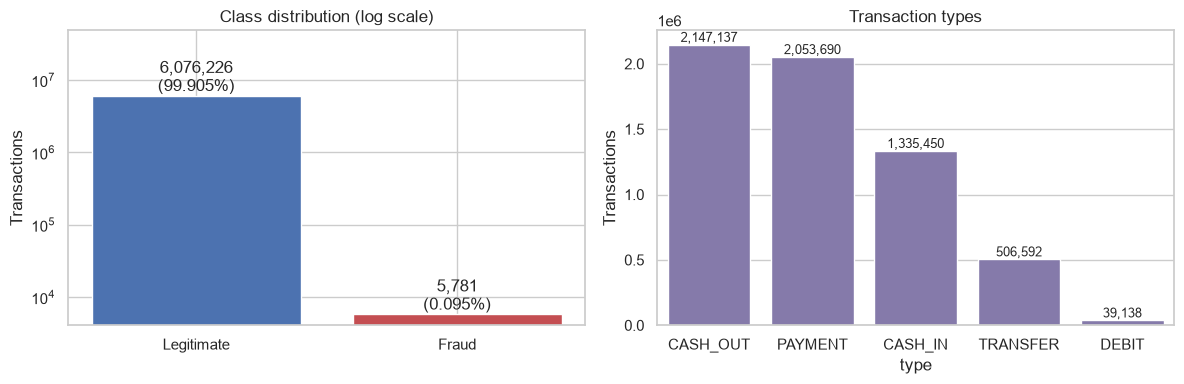

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
cnt = d_all.isFraud.value_counts().sort_index()
ax[0].bar(["Legitimate", "Fraud"], cnt.values, color=[COL_LEGIT, COL_FRAUD]); ax[0].set_yscale("log")
for i, v in enumerate(cnt.values):
    ax[0].text(i, v, f"{v:,}\n({v/cnt.sum():.3%})", ha="center", va="bottom")
ax[0].set_title("Class distribution (log scale)"); ax[0].set_ylabel("Transactions"); ax[0].set_ylim(top=cnt.max() * 8)

tc = d_all.type.value_counts()
sns.barplot(x=tc.index.astype(str), y=tc.values, ax=ax[1], color="#8172B2")
for i, v in enumerate(tc.values):
    ax[1].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
ax[1].set_title("Transaction types"); ax[1].set_ylabel("Transactions")
save_fig("01_class_and_type_distribution.png")

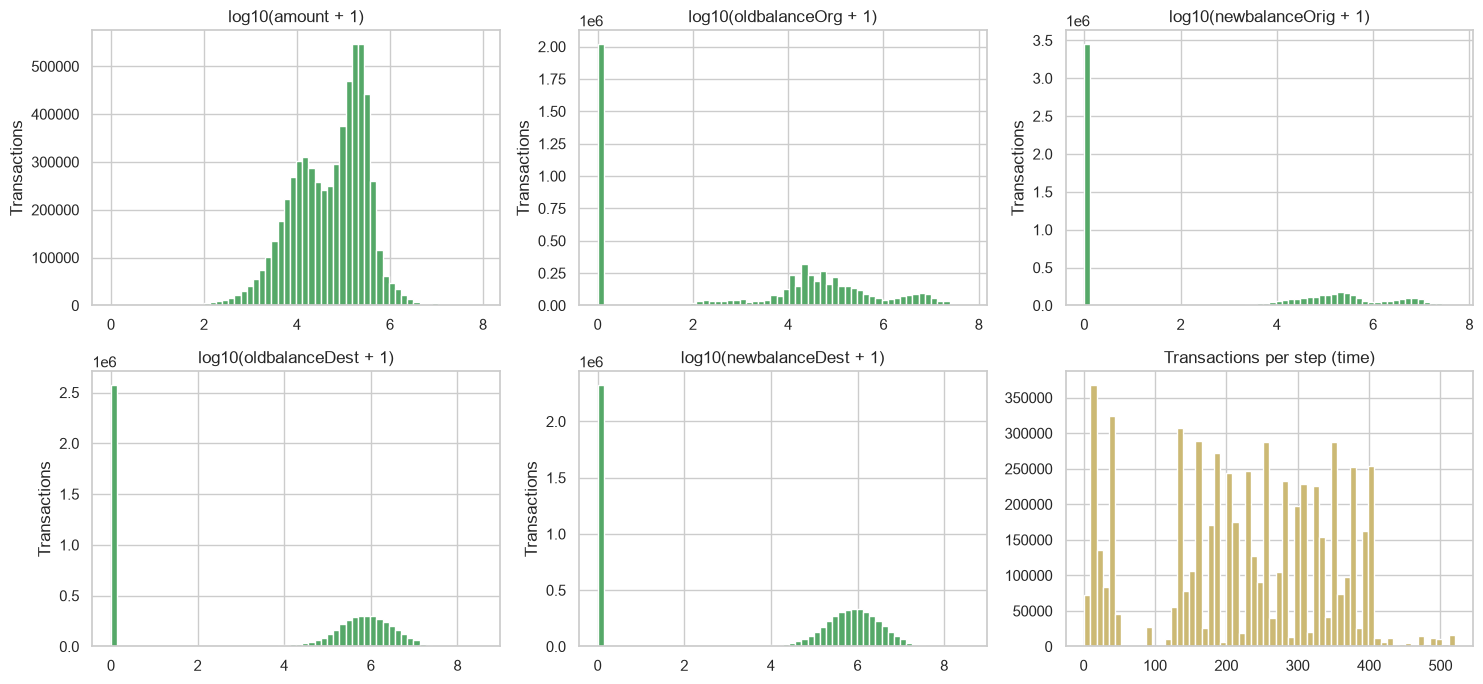

,skewness
amount,31.2105
oldbalanceOrg,5.2238
newbalanceOrig,5.1539
oldbalanceDest,19.8966
newbalanceDest,19.3652


In [20]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7)); axes = axes.ravel()
for a, c in zip(axes, num_cols):
    a.hist(np.log10(d_all[c] + 1), bins=60, color="#55A868"); a.set_title(f"log10({c} + 1)"); a.set_ylabel("Transactions")
axes[5].hist(d_all.step, bins=60, color="#CCB974"); axes[5].set_title("Transactions per step (time)")
save_fig("02_numeric_distributions.png")
skew = d_all[num_cols].skew().rename("skewness").to_frame()
display(skew)

Amounts and balances are extremely right-skewed (many zero balances, a few very large values), which is why log scales are used. The last panel shows how transaction volume per hour changes over time.

## 3.2 Bivariate analysis

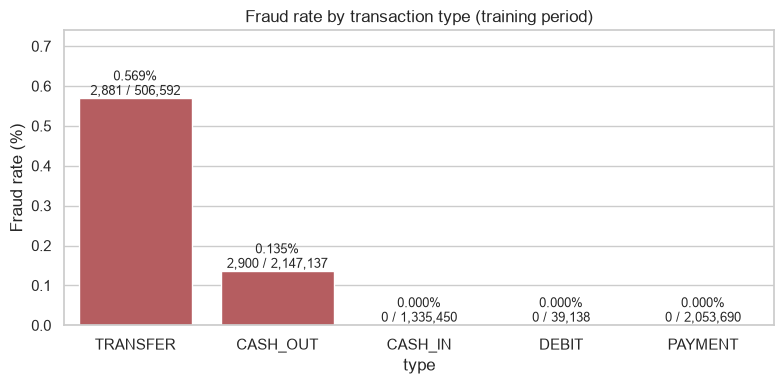

In [21]:
rate = d_all.groupby("type", observed=True).isFraud.agg(["mean", "sum", "count"]).sort_values("mean", ascending=False)
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=rate.index.astype(str), y=rate["mean"] * 100, ax=ax, color=COL_FRAUD)
for i, (m_, s_, c_) in enumerate(zip(rate["mean"], rate["sum"], rate["count"])):
    ax.text(i, m_ * 100, f"{m_:.3%}\n{int(s_):,} / {int(c_):,}", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("Fraud rate (%)"); ax.set_title("Fraud rate by transaction type (training period)"); ax.set_ylim(top=rate["mean"].max() * 100 * 1.3)
save_fig("03_fraud_rate_by_type.png")

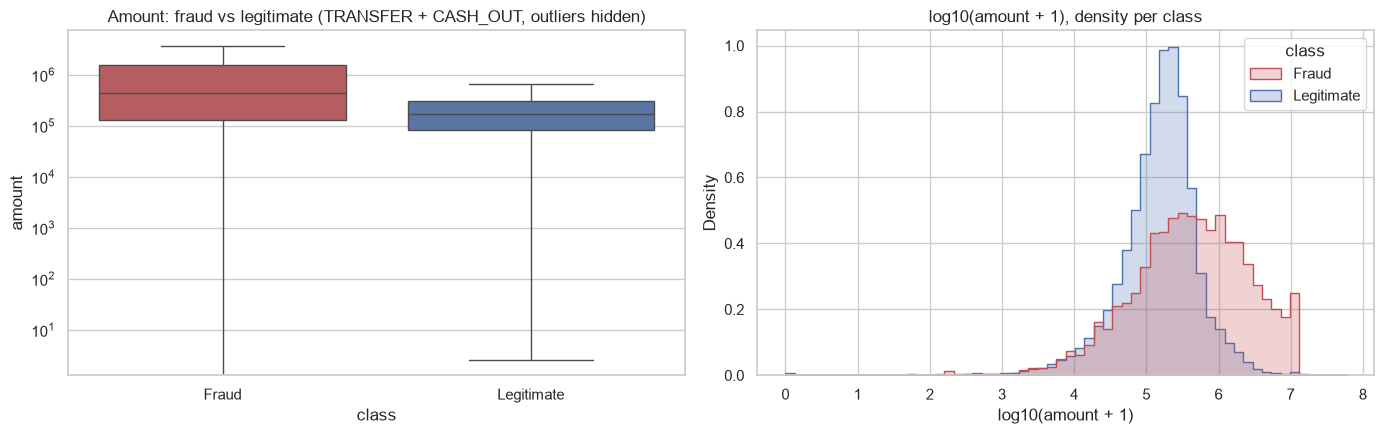

,count,mean,std,min,25%,50%,75%,95%,max
isFraud,,,,,,,,,
legitimate,"2,647,948.0000","315,732.5899","888,936.1103",0.0100,"83,069.6250","171,348.9400","306,606.4275","947,623.4450","92,445,516.6400"
fraud,"5,781.0000","1,458,053.9340","2,353,779.1626",0.0000,"128,133.0000","448,004.8600","1,534,985.0700","7,620,549.1400","10,000,000.0000"


In [22]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=plot_df, x="class", y="amount", palette=palette, ax=ax[0], showfliers=False); ax[0].set_yscale("log")
ax[0].set_title("Amount: fraud vs legitimate (TRANSFER + CASH_OUT, outliers hidden)")
sns.histplot(data=plot_df.assign(log_amount=np.log10(plot_df.amount + 1)), x="log_amount", hue="class", stat="density",
             common_norm=False, bins=60, palette=palette, ax=ax[1], element="step")
ax[1].set_title("log10(amount + 1), density per class"); ax[1].set_xlabel("log10(amount + 1)")
save_fig("04_amount_fraud_vs_legit.png")
q = d.groupby("isFraud").amount.describe(percentiles=[.25, .5, .75, .95]).rename(index={0: "legitimate", 1: "fraud"})
display(q)

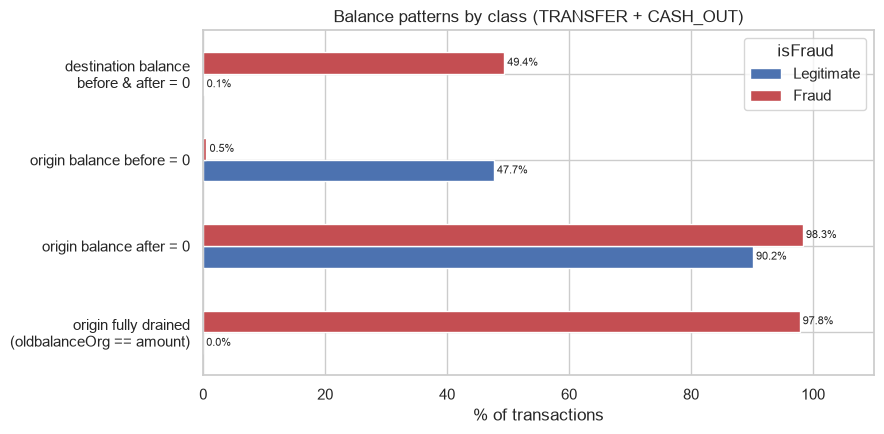

isFraud,Legitimate,Fraud
origin fully drained\n(oldbalanceOrg == amount),0.0000,97.8031
origin balance after = 0,90.1557,98.3394
origin balance before = 0,47.6801,0.5362
destination balance\nbefore & after = 0,0.0644,49.3686


In [23]:
flags = {
    "origin fully drained\n(oldbalanceOrg == amount)": d.drained,
    "origin balance after = 0": (d.newbalanceOrig == 0).astype(int),
    "origin balance before = 0": (d.oldbalanceOrg == 0).astype(int),
    "destination balance\nbefore & after = 0": d.dest_empty,
}
fl_df = pd.DataFrame({k: v.groupby(d.isFraud).mean() * 100 for k, v in flags.items()}).T.rename(columns={0: "Legitimate", 1: "Fraud"})
ax = fl_df.plot(kind="barh", color=[COL_LEGIT, COL_FRAUD], figsize=(9, 4.5))
ax.set_xlabel("% of transactions"); ax.set_title("Balance patterns by class (TRANSFER + CASH_OUT)")
for p in ax.patches:
    ax.text(p.get_width() + 0.5, p.get_y() + p.get_height() / 2, f"{p.get_width():.1f}%", va="center", fontsize=8)
ax.set_xlim(0, 110)
save_fig("05_balance_patterns_by_class.png")
display(fl_df)

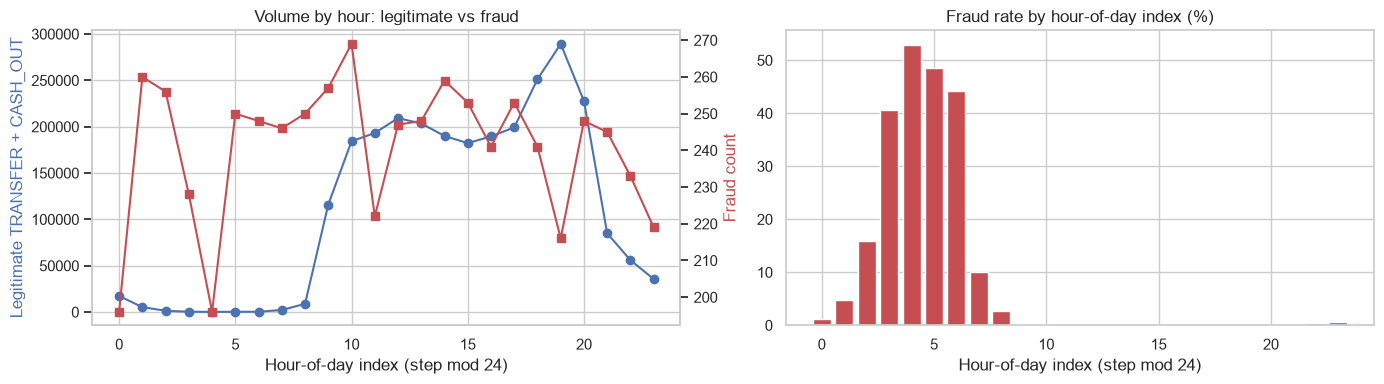

In [24]:
hr = d.groupby(["hour", "isFraud"]).size().unstack(fill_value=0).rename(columns={0: "legit", 1: "fraud"})
hr["fraud_rate_%"] = hr.fraud / (hr.fraud + hr.legit) * 100
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(hr.index, hr.legit, color=COL_LEGIT, marker="o", label="Legitimate"); ax[0].set_xlabel("Hour-of-day index (step mod 24)")
ax[0].set_ylabel("Legitimate TRANSFER + CASH_OUT", color=COL_LEGIT)
a2 = ax[0].twinx(); a2.plot(hr.index, hr.fraud, color=COL_FRAUD, marker="s", label="Fraud"); a2.set_ylabel("Fraud count", color=COL_FRAUD)
ax[0].set_title("Volume by hour: legitimate vs fraud"); a2.grid(False)
ax[1].bar(hr.index, hr["fraud_rate_%"], color=COL_FRAUD); ax[1].set_title("Fraud rate by hour-of-day index (%)"); ax[1].set_xlabel("Hour-of-day index (step mod 24)")
save_fig("06_hourly_pattern.png")

## 3.3 Multivariate analysis

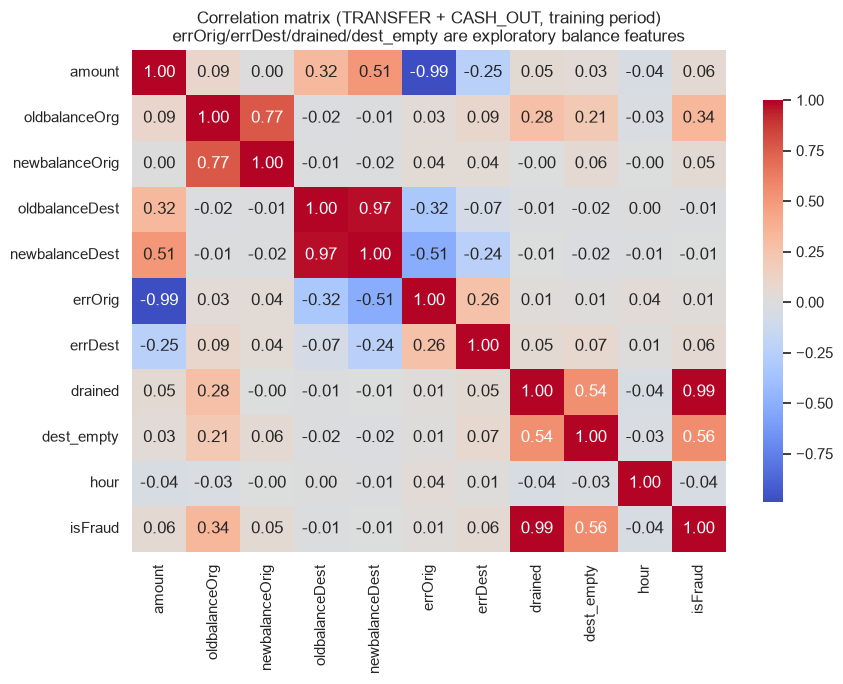

,corr_with_isFraud
drained,0.9889
dest_empty,0.5550
oldbalanceOrg,0.3357
amount,0.0594
errDest,0.0584
newbalanceOrig,0.0455
hour,-0.0439
errOrig,0.0148
oldbalanceDest,-0.0135
newbalanceDest,-0.0083


In [25]:
corr_cols = ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest", "errOrig", "errDest", "drained", "dest_empty", "hour", "isFraud"]
corr = d[corr_cols].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, cbar_kws={"shrink": .8})
ax.set_title("Correlation matrix (TRANSFER + CASH_OUT, training period)\nerrOrig/errDest/drained/dest_empty are exploratory balance features")
save_fig("07_correlation_heatmap.png")
display(corr["isFraud"].drop("isFraud").sort_values(key=abs, ascending=False).to_frame("corr_with_isFraud"))

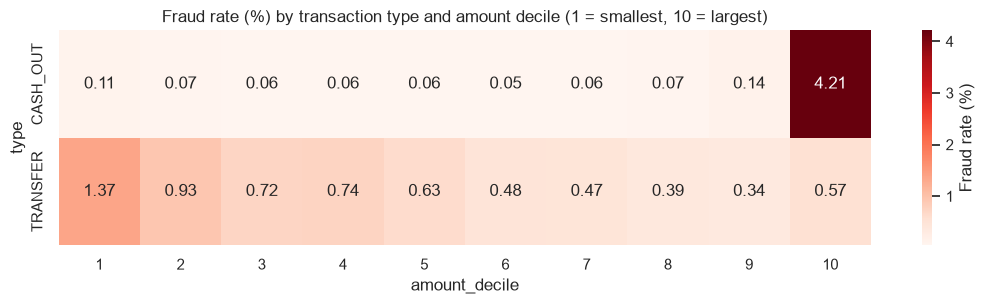

mean        sum          count      
drained       0      1   0     1        0     1
type                                           
CASH_OUT 0.0000 1.0000  31  2869  2144268  2869
TRANSFER 0.0002 1.0000  96  2785   503807  2785

In [26]:
d["amount_decile"] = pd.qcut(d.amount.rank(method="first"), 10, labels=False) + 1
hm = d.pivot_table(index="type", columns="amount_decile", values="isFraud", aggfunc="mean", observed=True) * 100
fig, ax = plt.subplots(figsize=(11, 3.2))
sns.heatmap(hm, annot=True, fmt=".2f", cmap="Reds", ax=ax, cbar_kws={"label": "Fraud rate (%)"})
ax.set_title("Fraud rate (%) by transaction type and amount decile (1 = smallest, 10 = largest)")
save_fig("08_fraud_rate_type_by_amount_decile.png")
dr = d.pivot_table(index="type", columns="drained", values="isFraud", aggfunc=["mean", "sum", "count"], observed=True)
display(dr)

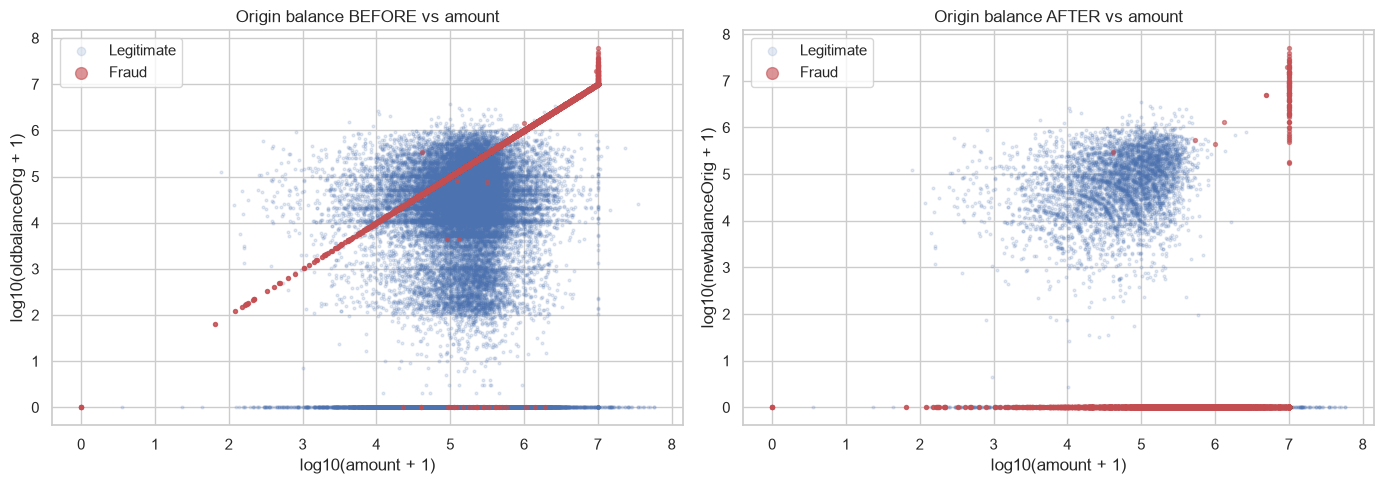

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, y, ttl in zip(ax, ["oldbalanceOrg", "newbalanceOrig"], ["Origin balance BEFORE", "Origin balance AFTER"]):
    for cls, col, al, sz in [("Legitimate", COL_LEGIT, .15, 4), ("Fraud", COL_FRAUD, .6, 8)]:
        s = plot_df[plot_df["class"] == cls]
        a.scatter(np.log10(s.amount + 1), np.log10(s[y] + 1), s=sz, alpha=al, color=col, label=cls)
    a.set_xlabel("log10(amount + 1)"); a.set_ylabel(f"log10({y} + 1)"); a.set_title(f"{ttl} vs amount"); a.legend(markerscale=3)
save_fig("09_amount_vs_origin_balance.png")

## 3.4 Analytical insights (computed from the training period)
The text below is generated by code from the data, so every figure is traceable.

In [28]:
r_type = d_all.groupby("type", observed=True).isFraud.mean()
n_zero_types = int((r_type == 0).sum()); zero_types = ", ".join(r_type.index[r_type == 0].astype(str))
med = d.groupby("isFraud").amount.median(); p95 = d.groupby("isFraud").amount.quantile(.95)
dr_rate = d.groupby("isFraud").drained.mean() * 100
rec_f = (d.loc[d.isFraud == 1, "errOrig"].abs() <= 0.01).mean() * 100
rec_l = (d.loc[d.isFraud == 0, "errOrig"].abs() <= 0.01).mean() * 100
drained_fraud_rate = d.loc[d.drained == 1, "isFraud"].mean() * 100
not_drained_fraud_rate = d.loc[d.drained == 0, "isFraud"].mean() * 100
night = hr.loc[[3, 4, 5]]; day = hr.loc[[10, 11, 12, 13, 14]]
display(Markdown(f'''
**Insight 1 — Fraud is concentrated in two transaction types.** Fraud appears only in TRANSFER ({r_type['TRANSFER']:.3%} of its rows) and CASH_OUT ({r_type['CASH_OUT']:.3%}); the {n_zero_types} other types ({zero_types}) have **zero** frauds in the training period. This matches the typical account-takeover pattern: move money out, then cash it out. *Hypothesis:* scoring effort can be focused on these two types.

**Insight 2 — Fraudulent transactions are much larger.** Within TRANSFER + CASH_OUT the median fraud amount is **{med[1]:,.0f}** vs **{med[0]:,.0f}** for legitimate rows ({med[1]/med[0]:.1f}x), and the 95th percentile is {p95[1]:,.0f} vs {p95[0]:,.0f}. Amount alone is informative but overlaps heavily, so it cannot be used by itself.

**Insight 3 — Fraud typically empties the origin account.** **{dr_rate[1]:.1f}%** of frauds have `oldbalanceOrg == amount` (account fully drained), compared with **{dr_rate[0]:.2f}%** of legitimate rows. Transactions with a drained origin have a fraud rate of **{drained_fraud_rate:.2f}%** vs **{not_drained_fraud_rate:.3f}%** otherwise (base rate in TRANSFER + CASH_OUT: {d.isFraud.mean():.3%}). *Hypothesis:* balance-change features are the key signal for the model.

**Insight 4 — Balance bookkeeping behaves differently for fraud.** The origin-balance identity (`old - amount = new`) holds for **{rec_f:.1f}%** of frauds but only **{rec_l:.1f}%** of legitimate rows, and destination accounts of fraud are often empty before and after the transaction ({d.loc[d.isFraud==1,'dest_empty'].mean()*100:.1f}% of frauds vs {d.loc[d.isFraud==0,'dest_empty'].mean()*100:.1f}% of legitimate rows). This is a very sharp separation, which is likely a **property of the simulation** and probably too clean for real-world data.

**Insight 5 — The hourly fraud-rate pattern is mostly a volume effect.** The fraud rate by hour-of-day index peaks around hours 3–5 (average {night['fraud_rate_%'].mean():.1f}% vs {day['fraud_rate_%'].mean():.2f}% around hours 10–14), but this is because legitimate volume drops overnight (about {night.legit.mean():,.0f} legit rows per hour vs {day.legit.mean():,.0f}) while fraud counts stay flat-ish ({night.fraud.mean():.0f} vs {day.fraud.mean():.0f} per hour). *Hypothesis:* hour-of-day should be treated cautiously: it may help in this simulation but is unlikely to generalize to a real wallet.
'''))


**Insight 1 — Fraud is concentrated in two transaction types.** Fraud appears only in TRANSFER (0.569% of its rows) and CASH_OUT (0.135%); the 3 other types (CASH_IN, DEBIT, PAYMENT) have **zero** frauds in the training period. This matches the typical account-takeover pattern: move money out, then cash it out. *Hypothesis:* scoring effort can be focused on these two types.

**Insight 2 — Fraudulent transactions are much larger.** Within TRANSFER + CASH_OUT the median fraud amount is **448,005** vs **171,349** for legitimate rows (2.6x), and the 95th percentile is 7,620,549 vs 947,623. Amount alone is informative but overlaps heavily, so it cannot be used by itself.

**Insight 3 — Fraud typically empties the origin account.** **97.8%** of frauds have `oldbalanceOrg == amount` (account fully drained), compared with **0.00%** of legitimate rows. Transactions with a drained origin have a fraud rate of **100.00%** vs **0.005%** otherwise (base rate in TRANSFER + CASH_OUT: 0.218%). *Hypothesis:* balance-change features are the key signal for the model.

**Insight 4 — Balance bookkeeping behaves differently for fraud.** The origin-balance identity (`old - amount = new`) holds for **99.4%** of frauds but only **9.4%** of legitimate rows, and destination accounts of fraud are often empty before and after the transaction (49.4% of frauds vs 0.1% of legitimate rows). This is a very sharp separation, which is likely a **property of the simulation** and probably too clean for real-world data.

**Insight 5 — The hourly fraud-rate pattern is mostly a volume effect.** The fraud rate by hour-of-day index peaks around hours 3–5 (average 47.3% vs 0.13% around hours 10–14), but this is because legitimate volume drops overnight (about 258 legit rows per hour vs 196,051) while fraud counts stay flat-ish (225 vs 249 per hour). *Hypothesis:* hour-of-day should be treated cautiously: it may help in this simulation but is unlikely to generalize to a real wallet.


### 3.5 A warning from the EDA: a one-line rule already separates the classes
Insight 3 suggests that the single condition "origin account fully drained" may be almost enough. We measure it on the **training period only** (validation and test remain unseen) so that later models are compared against an honest, very strong benchmark.

In [29]:
rule_pred = d.drained
tp = int(((rule_pred == 1) & (d.isFraud == 1)).sum()); fp = int(((rule_pred == 1) & (d.isFraud == 0)).sum()); fn = int(((rule_pred == 0) & (d.isFraud == 1)).sum())
print(f"Rule 'origin fully drained' on the training period (TRANSFER + CASH_OUT): TP={tp:,}  FP={fp:,}  FN={fn:,}")
print(f"Precision = {tp/(tp+fp):.4f} | Recall = {tp/(tp+fn):.4f}")
miss = d[(d.isFraud == 1) & (d.drained == 0)]
print(f"The {len(miss)} frauds missed by the rule: types {miss.type.value_counts().to_dict()}, median amount {miss.amount.median():,.0f}, "
      f"share with oldbalanceOrg == 0: {(miss.oldbalanceOrg == 0).mean():.1%}")

Rule 'origin fully drained' on the training period (TRANSFER + CASH_OUT): TP=5,654  FP=0  FN=127
Precision = 1.0000 | Recall = 0.9780
The 127 frauds missed by the rule: types {'TRANSFER': 96, 'CASH_OUT': 31}, median amount 10,000,000, share with oldbalanceOrg == 0: 24.4%


This does **not** mean the project is trivial. It means: (1) a simple rule becomes a strong, explainable **second baseline** in Phase 6; (2) the machine-learning model must be judged by what it adds on the *harder* cases (the frauds that do not drain the account); (3) this is very likely a feature of the **simulation**, so we will be careful not to over-claim real-world performance.

### Phases 1–3 summary
- **Completed:** problem framing, dataset audit (size, dtypes, missing values, duplicates, target balance, leakage review), data dictionary, chronological split definition, and EDA on the training period only.
- **Key decisions:** exclude `isFlaggedFraud` and account IDs; restrict deeper modeling analysis to TRANSFER and CASH_OUT (only types containing fraud); keep validation/test at their natural prevalence; time-based split (train steps 1–520, validation 521–631, test 632–743).
- **Key limitations:** PaySim is simulated (balance patterns are unrealistically clean); prevalence differs between periods; post-transaction balances are assumed to be available at scoring time.
- **Next:** Phase 4 (leak-free preprocessing + feature engineering) and Phase 5 (class imbalance).

## Phase 4 - Data Preprocessing and Feature Engineering

Model only `TRANSFER` and `CASH_OUT`, the transaction types containing fraud in this dataset. Keep the chronological train, validation, and test periods separate. Fit preprocessing on training data only; validation and test data are transformed, never used to fit it.

Drop account IDs and `isFlaggedFraud`. Create row-level balance-change features, then use an imputer, signed log transform, scaler, and one-hot encoding inside a scikit-learn pipeline.

In [30]:
import fraud_features as ff
print("Feature module ready:", ff.ENGINEERED)

Feature module ready: ['delta_orig', 'delta_dest', 'err_orig', 'err_dest', 'amount_to_old_orig', 'orig_drained', 'orig_emptied', 'dest_empty']


### 4.2 Load model columns and split chronologically

Reload only the columns needed for modeling. Validation and test keep their original prevalence; only training data may be resampled later.

In [31]:
for name in ["df_train", "d_all", "d", "plot_df", "fraud_part", "legit_part", "hr", "corr", "hm", "dr", "fl_df", "rate", "q", "flags", "miss", "rule_pred"]:
    globals().pop(name, None)
gc.collect()

from sklearn.metrics import average_precision_score, roc_auc_score, precision_score, recall_score, f1_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

model_columns = ["step", "type", "amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest", "isFraud"]
raw = load_paysim(usecols=model_columns)
raw["period"] = np.select(
    [raw.step <= TRAIN_END, raw.step <= VAL_END],
    ["train", "validation"],
    default="test",
)
in_scope = raw.type.isin(ff.IN_SCOPE_TYPES)

scope_summary = pd.DataFrame({
    "rows": raw.groupby("period", observed=True).size(),
    "frauds": raw.groupby("period", observed=True).isFraud.sum(),
    "rows_out_of_scope": raw.loc[~in_scope].groupby("period", observed=True).size(),
    "frauds_out_of_scope": raw.loc[~in_scope].groupby("period", observed=True).isFraud.sum(),
})
display(scope_summary)

model_data = raw.loc[in_scope].copy()
model_data["type"] = model_data["type"].astype(str)
del raw, in_scope
gc.collect()

train = model_data.loc[model_data.period == "train"]
val = model_data.loc[model_data.period == "validation"]
test = model_data.loc[model_data.period == "test"]
assert train.step.max() < val.step.min() and val.step.max() < test.step.min(), "Time periods overlap"

X_train, y_train = train[ff.RAW_FEATURES], train.isFraud.to_numpy()
X_val, y_val = val[ff.RAW_FEATURES], val.isFraud.to_numpy()
X_test, y_test = test[ff.RAW_FEATURES], test.isFraud.to_numpy()

split_summary_model = pd.DataFrame({
    "rows": [len(train), len(val), len(test)],
    "frauds": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
}, index=["train", "validation", "test"])
split_summary_model["fraud_prevalence_%"] = split_summary_model.frauds / split_summary_model.rows * 100
display(split_summary_model)

,rows,frauds,rows_out_of_scope,frauds_out_of_scope
period,,,,
test,89466,1252,51487,0
train,6082007,5781,3428278,0
validation,191147,1180,112446,0


,rows,frauds,fraud_prevalence_%
train,2653729,5781,0.2178
validation,78701,1180,1.4993
test,37979,1252,3.2966


### 4.3 Training sample, feature audit, and preprocessing

Keep every training fraud and sample legitimate training rows to control memory use. Validation and test data are not sampled. The feature audit is descriptive and uses training data only.

In [32]:
fraud_index = train.index[train.isFraud == 1]
legitimate_index = train.index[train.isFraud == 0]
legitimate_sample_index = rng.choice(legitimate_index.to_numpy(), size=min(300_000, len(legitimate_index)), replace=False)
training_sample_index = fraud_index.append(pd.Index(legitimate_sample_index))
X_train_model = train.loc[training_sample_index, ff.RAW_FEATURES]
y_train_model = train.loc[training_sample_index, "isFraud"].to_numpy()
print(f"Model training sample: {len(X_train_model):,} rows, {int(y_train_model.sum()):,} frauds")

feat_train = ff.add_features(X_train_model)
feature_scores = {}
for feature in ff.BALANCE_FEATURES + ff.ENGINEERED:
    score = feat_train[feature].fillna(0).to_numpy(dtype=float)
    feature_scores[feature] = max(
        average_precision_score(y_train_model, score),
        average_precision_score(y_train_model, -score),
    )
feature_audit = pd.Series(feature_scores, name="single-feature PR-AUC (training sample)").sort_values(ascending=False)
display(feature_audit.to_frame())
print(f"No-skill PR-AUC reference: {y_train_model.mean():.4%}")
del feat_train

def make_model_pipeline(**classifier_options):
    return Pipeline([
        ("preprocessor", ff.make_preprocessor(scale=True)),
        ("classifier", LogisticRegression(max_iter=200, **classifier_options)),
    ])

preprocessor = ff.make_preprocessor(scale=True)
preprocessor.fit(X_train_model)
train_preview = preprocessor.transform(X_train_model.iloc[:1000])
validation_preview = preprocessor.transform(X_val.iloc[:1000])
print("Preview shapes (train / validation):", train_preview.shape, validation_preview.shape)
print("NaNs after preprocessing:", int(np.isnan(train_preview).sum()), int(np.isnan(validation_preview).sum()))
del train_preview, validation_preview
gc.collect()

Model training sample: 305,781 rows, 5,781 frauds


,single-feature PR-AUC (training sample)
orig_drained,0.9784
delta_orig,0.6239
oldbalanceOrg,0.4846
dest_empty,0.4696
newbalanceDest,0.3594
err_dest,0.3298
delta_dest,0.1983
err_orig,0.1929
amount,0.1036
oldbalanceDest,0.0688


No-skill PR-AUC reference: 1.8906%
Preview shapes (train / validation): (1000, 15) (1000, 15)
NaNs after preprocessing: 0 0


214

## Phase 5 - Handling Class Imbalance

Compare class weighting, random under/oversampling, and no handling. All strategies fit only on the training sample; validation keeps its natural prevalence and the test set remains untouched. Metrics emphasize PR-AUC because fraud is rare.

In [33]:
from sklearn.metrics import precision_recall_curve

def eval_scores(y_true, probabilities, threshold=0.5):
    predictions = (probabilities >= threshold).astype(int)
    precision, recall, _ = precision_recall_curve(y_true, probabilities)
    high_precision_recall = recall[precision >= 0.95]
    return {
        "PR-AUC": average_precision_score(y_true, probabilities),
        "ROC-AUC": roc_auc_score(y_true, probabilities),
        "precision@0.5": precision_score(y_true, predictions, zero_division=0),
        "recall@0.5": recall_score(y_true, predictions),
        "F1@0.5": f1_score(y_true, predictions),
        "recall@precision>=0.95": high_precision_recall.max() if len(high_precision_recall) else 0.0,
    }

strategies = {
    "No handling": ff.ResampledClassifier(make_model_pipeline(), "none"),
    "Class weights": ff.ResampledClassifier(make_model_pipeline(class_weight="balanced"), "none"),
    "Undersample 1:10": ff.ResampledClassifier(make_model_pipeline(), "under", 0.1, RANDOM_STATE),
    "Undersample 1:1": ff.ResampledClassifier(make_model_pipeline(), "under", 1.0, RANDOM_STATE),
    "Oversample 1:10": ff.ResampledClassifier(make_model_pipeline(), "over", 0.1, RANDOM_STATE),
}

strategy_results = {}
for strategy_name, model in strategies.items():
    started = time.time()
    model.fit(X_train_model, y_train_model)
    validation_probabilities = model.predict_proba(X_val)[:, 1]
    strategy_results[strategy_name] = {
        **eval_scores(y_val, validation_probabilities),
        "rows_used_to_fit": model.n_fit_rows_,
        "frauds_in_fit": model.n_fit_frauds_,
        "fit_seconds": time.time() - started,
    }

results = pd.DataFrame(strategy_results).T
results_display = results.copy()
results_display[["rows_used_to_fit", "frauds_in_fit"]] = results_display[["rows_used_to_fit", "frauds_in_fit"]].astype(int)
display(results_display)
print(f"No-skill validation PR-AUC (prevalence): {y_val.mean():.4%}")

,PR-AUC,ROC-AUC,precision@0.5,recall@0.5,F1@0.5,recall@precision>=0.95,rows_used_to_fit,frauds_in_fit,fit_seconds
No handling,0.9979,0.9991,1.0000,0.9975,0.9987,0.9975,305781,5781,2.7210
Class weights,1.0000,1.0000,0.9992,0.9983,0.9987,1.0000,305781,5781,4.9545
Undersample 1:10,0.9982,0.9991,1.0000,0.9975,0.9987,0.9975,63591,5781,0.6959
Undersample 1:1,0.9992,1.0000,0.9941,0.9983,0.9962,0.9983,11562,5781,0.3714
Oversample 1:10,0.9982,0.9993,1.0000,0.9975,0.9987,0.9975,330000,30000,4.2611


No-skill validation PR-AUC (prevalence): 1.4993%


In [34]:
best_ap = results["PR-AUC"].max()
strategies_within_tolerance = results.index[results["PR-AUC"] >= best_ap - 0.002]
STRATEGY = "Class weights" if "Class weights" in strategies_within_tolerance else results["PR-AUC"].idxmax()
print(f"Best validation PR-AUC: {best_ap:.4f}")
print("Strategies within 0.002 of best:", list(strategies_within_tolerance))
print("Selected strategy:", STRATEGY)

Best validation PR-AUC: 1.0000
Strategies within 0.002 of best: ['Class weights', 'Undersample 1:10', 'Undersample 1:1', 'Oversample 1:10']
Selected strategy: Class weights


### Phase 4-5 summary

- Features are computed from each transaction's own balance fields; identifiers and `isFlaggedFraud` are excluded.
- The preprocessing pipeline is fitted on the training sample only. Validation and test periods retain their natural class distribution.
- The training sample keeps every fraud, 300,000 to be handled right and  randomly sampled legitimate rows to make model comparisons practical.
- Five logistic-regression imbalance strategies were compared on validation PR-AUC. The selected strategy is class weighting when results are within 0.002 of the best.
- Scores are unusually high because PaySim is simulated and balance-derived features are exceptionally predictive; do not treat these results as expected production performance.

# Phase 6 - Machine Learning Modeling

Compare a no-skill baseline, an explainable balance rule, and four classifiers. Fit each classifier on the sampled training period and compare on validation data. The test period remains locked.

In [35]:
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier


def model_pipeline(classifier, scale=False):
    return Pipeline([
        ("preprocessor", ff.make_preprocessor(scale=scale)),
        ("classifier", classifier),
    ])


def make_models():
    return {
        "Logistic Regression": ff.ResampledClassifier(
            model_pipeline(LogisticRegression(max_iter=300, class_weight="balanced"), scale=True),
            "none",
        ),
        "Decision Tree": ff.ResampledClassifier(
            model_pipeline(DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=RANDOM_STATE)),
            "under", 0.1, RANDOM_STATE,
        ),
        "Random Forest": ff.ResampledClassifier(
            model_pipeline(RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE)),
            "under", 0.1, RANDOM_STATE,
        ),
        "Gradient Boosting": ff.ResampledClassifier(
            model_pipeline(HistGradientBoostingClassifier(max_iter=100, learning_rate=0.1, random_state=RANDOM_STATE)),
            "under", 0.1, RANDOM_STATE,
        ),
    }

rows = {}
dummy = DummyClassifier(strategy="prior").fit(X_train_model, y_train_model)
rows["Baseline: Dummy (prior)"] = {
    **eval_scores(y_val, dummy.predict_proba(X_val)[:, 1]),
    "fit_seconds": 0.0,
}
rule_score = ff.add_features(X_val)["orig_drained"].to_numpy(dtype=float)
rows["Baseline: rule 'account drained'"] = {
    **eval_scores(y_val, rule_score),
    "fit_seconds": 0.0,
}

fitted_v1 = {}
for model_name, model in make_models().items():
    started = time.time()
    model.fit(X_train_model, y_train_model)
    fitted_v1[model_name] = model
    validation_probabilities = model.predict_proba(X_val)[:, 1]
    rows[model_name] = {
        **eval_scores(y_val, validation_probabilities),
        "fit_seconds": time.time() - started,
    }

res6 = pd.DataFrame(rows).T
display(res6)
print(f"Validation fraud prevalence (no-skill PR-AUC): {y_val.mean():.4%}")

,PR-AUC,ROC-AUC,precision@0.5,recall@0.5,F1@0.5,recall@precision>=0.95,fit_seconds
Baseline: Dummy (prior),0.0150,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000
Baseline: rule 'account drained',0.9841,0.9919,1.0000,0.9839,0.9919,0.9839,0.0000
Logistic Regression,1.0000,1.0000,0.9992,0.9983,0.9987,1.0000,6.4250
Decision Tree,0.9999,1.0000,1.0000,0.9975,0.9987,1.0000,1.5635
Random Forest,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,9.7316
Gradient Boosting,1.0000,1.0000,0.9992,1.0000,0.9996,1.0000,3.2169


Validation fraud prevalence (no-skill PR-AUC): 1.4993%




### Phase 6 summary

- Two baselines and four classifiers are compared using the same training sample and validation period.
- The test set remains locked.
- PaySim's synthetic balance patterns make results unusually strong; do not treat them as expected production performance.

In [36]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

raw_money_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(ff.signed_log1p, feature_names_out="one-to-one")),
    ("scaler", StandardScaler()),
])
raw_preprocessor = ColumnTransformer([
    ("money", raw_money_pipeline, ff.BALANCE_FEATURES),
    ("type", OneHotEncoder(categories=[ff.IN_SCOPE_TYPES], handle_unknown="ignore"), ["type"]),
], remainder="drop")
raw_logistic = ff.ResampledClassifier(
    Pipeline([
        ("preprocessor", raw_preprocessor),
        ("classifier", LogisticRegression(max_iter=300, class_weight="balanced")),
    ]),
    "none",
)
raw_logistic.fit(X_train_model, y_train_model)
raw_probabilities = raw_logistic.predict_proba(X_val)[:, 1]
all_feature_ap = res6.loc["Logistic Regression", "PR-AUC"]
raw_feature_ap = average_precision_score(y_val, raw_probabilities)
display(pd.DataFrame({
    "PR-AUC": [all_feature_ap, raw_feature_ap],
}, index=["Engineered features", "Raw columns only"]))

,PR-AUC
Engineered features,1.0000
Raw columns only,0.8719


## Phase 7 - Time-aware Cross-Validation and Hyperparameter Tuning

Use expanding time windows within the sampled training data. Each fold trains only on earlier transaction steps and validates on a later block. Tune logistic-regression regularization by average precision.

In [37]:
from sklearn.model_selection import GridSearchCV

CV_CUTS = [260, 345, 430, 520]
sample_steps = train.loc[X_train_model.index, "step"].to_numpy()
cv_splits = []
fold_rows = []
for fold_number, (train_end, validation_end) in enumerate(zip(CV_CUTS[:-1], CV_CUTS[1:]), 1):
    train_indices = np.flatnonzero(sample_steps <= train_end)
    validation_indices = np.flatnonzero((sample_steps > train_end) & (sample_steps <= validation_end))
    cv_splits.append((train_indices, validation_indices))
    fold_rows.append({
        "fold": fold_number,
        "train_steps": f"1-{train_end}",
        "validation_steps": f"{train_end + 1}-{validation_end}",
        "train_rows": len(train_indices),
        "train_frauds": int(y_train_model[train_indices].sum()),
        "validation_rows": len(validation_indices),
        "validation_frauds": int(y_train_model[validation_indices].sum()),
    })
display(pd.DataFrame(fold_rows).set_index("fold"))

logistic_search = GridSearchCV(
    ff.ResampledClassifier(
        make_model_pipeline(class_weight="balanced"),
        "none",
        random_state=RANDOM_STATE,
    ),
    param_grid={"estimator__classifier__C": [0.1, 1.0, 10.0]},
    scoring="average_precision",
    cv=cv_splits,
    n_jobs=1,
    refit=True,
    error_score="raise",
)
logistic_search.fit(X_train_model, y_train_model)
print("Best CV average precision:", f"{logistic_search.best_score_:.4f}")
print("Best parameters:", logistic_search.best_params_)
print("Test data has not been used for tuning or model selection.")

,train_steps,validation_steps,train_rows,train_frauds,validation_rows,validation_frauds
fold,,,,,,
1,1-260,261-345,180225,2925,60857,930
2,1-345,346-430,241082,3855,60372,992
3,1-430,431-520,301454,4847,4327,934


Best CV average precision: 0.9987
Best parameters: {'estimator__classifier__C': 10.0}
Test data has not been used for tuning or model selection.


### 7.1 Tuned logistic regression on validation

The regularization parameter is selected using training-only time folds. Score the refitted estimator on validation once for comparison.

In [38]:
tuned_logistic = logistic_search.best_estimator_
tuned_validation_scores = eval_scores(y_val, tuned_logistic.predict_proba(X_val)[:, 1])
display(pd.Series(tuned_validation_scores, name="tuned logistic regression on validation").to_frame())

,tuned logistic regression on validation
PR-AUC,1.0000
ROC-AUC,1.0000
precision@0.5,0.9992
recall@0.5,0.9983
F1@0.5,0.9987
recall@precision>=0.95,1.0000


### Phase 7 summary

- Expanding-window folds preserve time order and are built from the sampled training data only.
- Logistic-regression regularization was tuned by average precision; the test period was not used.
- Validation results remain unusually high because the PaySim simulation contains strong balance-pattern signals.

# Phase 8 - Final Evaluation on the Untouched Test Set

The selected model was fitted using training data only.

In [39]:
from sklearn.metrics import confusion_matrix, roc_curve

final_model = tuned_logistic
p_val = final_model.predict_proba(X_val)[:, 1]
p_test = final_model.predict_proba(X_test)[:, 1]
rule_test = ff.add_features(X_test)["orig_drained"].to_numpy(dtype=float)


def full_metrics(y_true, score, threshold):
    predictions = (score >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
    precision = tp / (tp + fp) if tp + fp else np.nan
    recall = tp / (tp + fn)
    return {
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn),
        "Precision": precision,
        "Recall": recall,
        "F1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
        "False-positive rate": fp / (fp + tn),
        "False-negative rate": fn / (fn + tp),
        "ROC-AUC": roc_auc_score(y_true, score),
        "PR-AUC": average_precision_score(y_true, score),
    }


dummy_test = dummy.predict_proba(X_test)[:, 1]
test_tbl = pd.DataFrame({
    "Tuned Logistic Regression (threshold 0.5)": full_metrics(y_test, p_test, 0.5),
    "Rule: account drained": full_metrics(y_test, rule_test, 0.5),
    "Dummy (prior)": full_metrics(y_test, dummy_test, 0.5),
}).T
display(test_tbl)
print(f"Test fraud prevalence (no-skill PR-AUC): {y_test.mean():.4%}")

,TP,FP,FN,TN,Precision,Recall,F1,False-positive rate,False-negative rate,ROC-AUC,PR-AUC
Tuned Logistic Regression (threshold 0.5),"1,248.0000",0.0000,4.0000,"36,727.0000",1.0000,0.9968,0.9984,0.0000,0.0032,1.0000,1.0000
Rule: account drained,"1,203.0000",0.0000,49.0000,"36,727.0000",1.0000,0.9609,0.9800,0.0000,0.0391,0.9804,0.9622
Dummy (prior),0.0000,0.0000,"1,252.0000","36,727.0000",NaN,0.0000,NaN,0.0000,1.0000,0.5000,0.0330


Test fraud prevalence (no-skill PR-AUC): 3.2966%


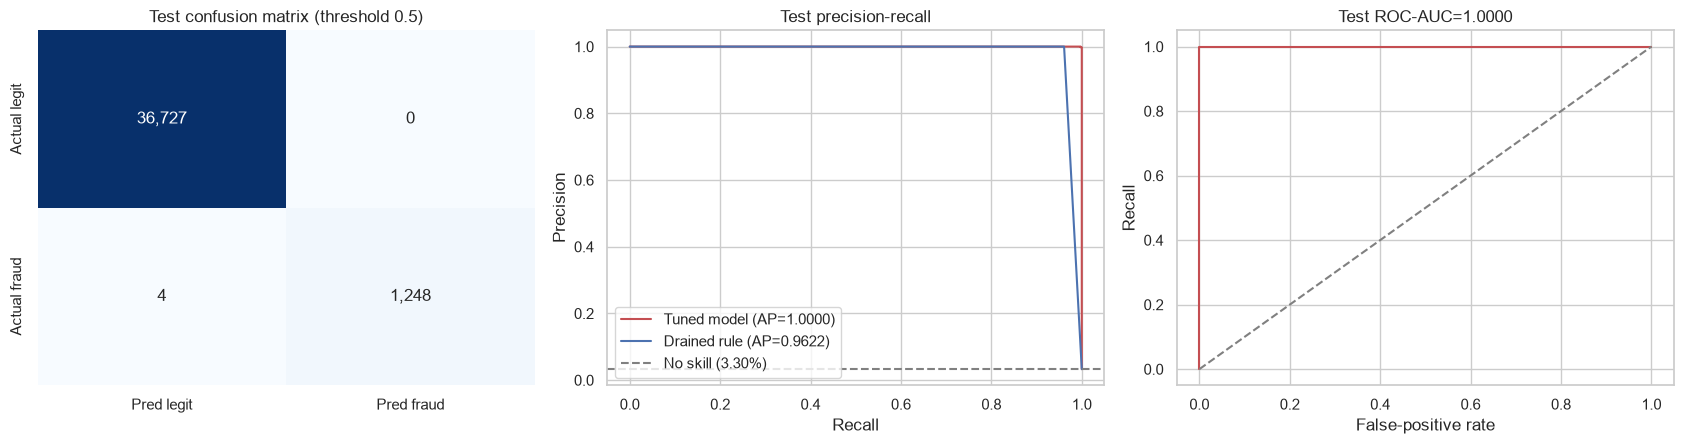

outcome,FN,TN,TP
type,,,
CASH_OUT,4,28526,622
TRANSFER,0,8201,626


Missed frauds at 0.5: 4 | false alarms: 0


,step,type,amount,score
6296015,671,CASH_OUT,0.0000,0.4809
6351226,702,CASH_OUT,0.0000,0.4332
6362461,730,CASH_OUT,0.0000,0.3572
6362585,741,CASH_OUT,0.0000,0.4017


In [40]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
confusion = confusion_matrix(y_test, (p_test >= 0.5).astype(int), labels=[0, 1])
sns.heatmap(
    confusion,
    annot=True,
    fmt=",d",
    cmap="Blues",
    cbar=False,
    ax=axes[0],
    xticklabels=["Pred legit", "Pred fraud"],
    yticklabels=["Actual legit", "Actual fraud"],
)
axes[0].set_title("Test confusion matrix (threshold 0.5)")

precision_model, recall_model, _ = precision_recall_curve(y_test, p_test)
precision_rule, recall_rule, _ = precision_recall_curve(y_test, rule_test)
axes[1].plot(recall_model, precision_model, color=COL_FRAUD, label=f"Tuned model (AP={average_precision_score(y_test, p_test):.4f})")
axes[1].plot(recall_rule, precision_rule, color=COL_LEGIT, label=f"Drained rule (AP={average_precision_score(y_test, rule_test):.4f})")
axes[1].axhline(y_test.mean(), color="gray", linestyle="--", label=f"No skill ({y_test.mean():.2%})")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Test precision-recall")
axes[1].legend(loc="lower left")

false_positive_rate, true_positive_rate, _ = roc_curve(y_test, p_test)
axes[2].plot(false_positive_rate, true_positive_rate, color=COL_FRAUD)
axes[2].plot([0, 1], [0, 1], "--", color="gray")
axes[2].set(xlabel="False-positive rate", ylabel="Recall", title=f"Test ROC-AUC={roc_auc_score(y_test, p_test):.4f}")
save_fig("10_test_evaluation.png")

error_data = test.copy()
error_data["score"] = p_test
error_data["prediction"] = (p_test >= 0.5).astype(int)
error_data["outcome"] = np.select(
    [
        (error_data.prediction == 1) & (error_data.isFraud == 1),
        (error_data.prediction == 1) & (error_data.isFraud == 0),
        (error_data.prediction == 0) & (error_data.isFraud == 1),
    ],
    ["TP", "FP", "FN"],
    default="TN",
)
display(pd.crosstab(error_data.type, error_data.outcome))
missed_frauds = error_data.loc[error_data.outcome == "FN", ["step", "type", "amount", "score"]]
false_alarms = error_data.loc[error_data.outcome == "FP", ["step", "type", "amount", "score"]]
print(f"Missed frauds at 0.5: {len(missed_frauds)} | false alarms: {len(false_alarms)}")
display(missed_frauds.sort_values("amount", ascending=False).head(10))

In [41]:

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Evaluate using the actual deployed threshold
threshold = 0.70

test_predictions = (p_test >= threshold).astype(int)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
).ravel()

# Calculate metrics
precision = precision_score(
    y_test, test_predictions, zero_division=0
)

recall = recall_score(
    y_test, test_predictions, zero_division=0
)

f1 = f1_score(
    y_test, test_predictions, zero_division=0
)

roc_auc = roc_auc_score(y_test, p_test)

pr_auc = average_precision_score(y_test, p_test)

print("FINAL TEST RESULTS AT 0.70 THRESHOLD")
print("-------------------------------------")
print("Threshold:", threshold)
print("Total transactions:", len(y_test))
print("True Positives:", tp)
print("False Positives:", fp)
print("True Negatives:", tn)
print("False Negatives:", fn)
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))
print("ROC-AUC:", round(roc_auc, 4))
print("PR-AUC:", round(pr_auc, 4))


FINAL TEST RESULTS AT 0.70 THRESHOLD
-------------------------------------
Threshold: 0.7
Total transactions: 37979
True Positives: 1247
False Positives: 0
True Negatives: 36727
False Negatives: 5
Precision: 1.0
Recall: 0.996
F1 Score: 0.998
ROC-AUC: 1.0
PR-AUC: 1.0


# Phase 9 - Cost-Based Threshold Optimization

The default 0.5 cutoff ignores the different costs of missed fraud and false alarms. I chose a threshold that minimizes estimated cost on validation data only, without changing the model or threshold.

**Illustrative assumptions:** a missed fraud costs the transaction amount, and each false alarm costs 500 currency units (penalty).

In [42]:
COST_ASSUMPTIONS = {"fn_loss_fraction": 1.0, "fp_cost": 500.0}
amount_val = val.amount.to_numpy()
amount_test = test.amount.to_numpy()
threshold_grid = np.unique(np.r_[np.logspace(-4, -0.01, 60), np.linspace(0.02, 0.98, 49)])


def sweep_thresholds(y_true, score, amount, grid):
    rows = []
    for threshold in grid:
        flagged = score >= threshold
        missed = (~flagged) & (y_true == 1)
        false_alarms = flagged & (y_true == 0)
        rows.append((threshold, amount[missed].sum(), int(false_alarms.sum()), int(missed.sum())))
    return pd.DataFrame(rows, columns=["threshold", "missed_fraud_amount", "false_alarms", "missed_frauds"])


def add_costs(sweep, fn_loss_fraction, fp_cost):
    costs = sweep.copy()
    costs["fn_cost"] = fn_loss_fraction * costs.missed_fraud_amount
    costs["fp_cost"] = fp_cost * costs.false_alarms
    costs["total_cost"] = costs.fn_cost + costs.fp_cost
    return costs


def choose_cost_threshold(costs, tolerance):
    values = costs.total_cost.to_numpy()
    minimum_index = int(np.argmin(values))
    allowed_extra_cost = max(0.01 * values[minimum_index], tolerance)
    lower = upper = minimum_index
    while lower > 0 and values[lower - 1] <= values[minimum_index] + allowed_extra_cost:
        lower -= 1
    while upper < len(values) - 1 and values[upper + 1] <= values[minimum_index] + allowed_extra_cost:
        upper += 1
    middle = (lower + upper) // 2
    return (
        float(costs.threshold.iloc[middle]),
        (float(costs.threshold.iloc[lower]), float(costs.threshold.iloc[upper])),
        float(values[minimum_index]),
    )


validation_sweep = sweep_thresholds(y_val, p_val, amount_val, threshold_grid)
validation_costs = add_costs(validation_sweep, **COST_ASSUMPTIONS)
flag_nothing_cost = COST_ASSUMPTIONS["fn_loss_fraction"] * amount_val[y_val == 1].sum()
flag_everything_cost = COST_ASSUMPTIONS["fp_cost"] * int((y_val == 0).sum())
T_STAR, threshold_plateau, minimum_validation_cost = choose_cost_threshold(
    validation_costs, COST_ASSUMPTIONS["fp_cost"]
)
print(f"Validation cost, flag nothing: {flag_nothing_cost:,.0f}")
print(f"Validation cost, flag everything: {flag_everything_cost:,.0f}")
print(f"Minimum validation cost: {minimum_validation_cost:,.0f}")
print(f"Near-optimal threshold range: {threshold_plateau[0]:.4f} to {threshold_plateau[1]:.4f}")
print(f"Selected validation threshold: {T_STAR:.4f}")

sensitivity_rows = []
for missed_loss_fraction in [0.5, 1.0]:
    for false_alarm_cost in [50.0, 500.0, 5_000.0]:
        sensitivity_costs = add_costs(validation_sweep, missed_loss_fraction, false_alarm_cost)
        threshold, plateau, minimum = choose_cost_threshold(sensitivity_costs, false_alarm_cost)
        sensitivity_rows.append({
            "missed_loss_fraction": missed_loss_fraction,
            "false_alarm_cost": false_alarm_cost,
            "threshold": threshold,
            "plateau_low": plateau[0],
            "plateau_high": plateau[1],
            "minimum_cost": minimum,
        })
display(pd.DataFrame(sensitivity_rows))


def policy_cost(y_true, score, amount, threshold):
    flagged = score >= threshold
    missed = (~flagged) & (y_true == 1)
    false_alarms = flagged & (y_true == 0)
    cost = COST_ASSUMPTIONS["fn_loss_fraction"] * amount[missed].sum()
    cost += COST_ASSUMPTIONS["fp_cost"] * false_alarms.sum()
    return cost, int(missed.sum()), int(false_alarms.sum())


test_cost_rows = {}
for policy_name, threshold in [("Selected validation threshold", T_STAR), ("Default 0.5", 0.5)]:
    cost, missed_count, false_alarm_count = policy_cost(y_test, p_test, amount_test, threshold)
    test_cost_rows[policy_name] = {
        "estimated_cost": cost,
        "missed_frauds": missed_count,
        "false_alarms": false_alarm_count,
    }
test_cost_rows["Flag nothing"] = {
    "estimated_cost": COST_ASSUMPTIONS["fn_loss_fraction"] * amount_test[y_test == 1].sum(),
    "missed_frauds": int(y_test.sum()),
    "false_alarms": 0,
}
test_cost_rows["Flag everything"] = {
    "estimated_cost": COST_ASSUMPTIONS["fp_cost"] * int((y_test == 0).sum()),
    "missed_frauds": 0,
    "false_alarms": int((y_test == 0).sum()),
}
test_cost = pd.DataFrame(test_cost_rows).T
display(test_cost)

Validation cost, flag nothing: 1,497,276,960
Validation cost, flag everything: 38,760,500
Minimum validation cost: 0
Near-optimal threshold range: 0.5000 to 0.9000
Selected validation threshold: 0.7000


,missed_loss_fraction,false_alarm_cost,threshold,plateau_low,plateau_high,minimum_cost
0,0.5000,50.0000,0.7000,0.5000,0.9000,0.0000
1,0.5000,500.0000,0.7000,0.5000,0.9000,0.0000
2,0.5000,"5,000.0000",0.7000,0.5000,0.9000,0.0000
3,1.0000,50.0000,0.7000,0.5000,0.9000,0.0000
4,1.0000,500.0000,0.7000,0.5000,0.9000,0.0000
5,1.0000,"5,000.0000",0.7000,0.5000,0.9000,0.0000


,estimated_cost,missed_frauds,false_alarms
Selected validation threshold,"10,000,000.0000",5.0000,0.0000
Default 0.5,0.0000,4.0000,0.0000
Flag nothing,"2,130,128,675.2100","1,252.0000",0.0000
Flag everything,"18,363,500.0000",0.0000,"36,727.0000"


# Phase 10 - Feature Importance and Business Interpretation

Use permutation importance on validation data to measure how much PR-AUC falls when each input column is shuffled. 

In [43]:
from sklearn.inspection import permutation_importance

importance_result = permutation_importance(
    final_model,
    X_val,
    y_val,
    scoring="average_precision",
    n_repeats=3,
    random_state=RANDOM_STATE,
    n_jobs=1,
)
importance = pd.DataFrame({
    "feature": X_val.columns,
    "PR-AUC drop (mean)": importance_result.importances_mean,
    "std": importance_result.importances_std,
}).sort_values("PR-AUC drop (mean)", ascending=False)
display(importance)

top_features = importance.head(3).feature.tolist()
display(Markdown(
    "**Top validation signals:** " + ", ".join(f"`{name}`" for name in top_features) +
    ". Shuffling each input reduces validation PR-AUC by the amount shown above."
))

,feature,PR-AUC drop (mean),std
2,oldbalanceOrg,0.9271,0.0042
1,amount,0.4710,0.0055
3,newbalanceOrig,0.0553,0.0007
4,oldbalanceDest,0.0108,0.0007
5,newbalanceDest,0.0002,0.0000
0,type,0.0000,0.0000


**Top validation signals:** `oldbalanceOrg`, `amount`, `newbalanceOrig`. Shuffling each input reduces validation PR-AUC by the amount shown above.

### 9.3 Save the final pipeline and evaluation scores

The app can load the fitted model and selected validation threshold instead of retraining. The exported score file contains validation and test scores for the dashboard.

In [44]:
import joblib
import sklearn

models_dir = Path("models")
models_dir.mkdir(parents=True, exist_ok=True)
model_name = "Tuned Logistic Regression"
bundle = {
    "pipeline": final_model,
    "threshold": float(T_STAR),
    "model_name": model_name,
    "input_columns": ff.RAW_FEATURES,
    "in_scope_types": ff.IN_SCOPE_TYPES,
    "cost_assumptions": COST_ASSUMPTIONS,
    "sklearn_version": sklearn.__version__,
    "trained_on_steps": f"1-{TRAIN_END}",
    "threshold_selected_on_steps": f"{TRAIN_END + 1}-{VAL_END}",
    "note": "Trained on simulated PaySim data; costs are illustrative assumptions.",
}
model_path = models_dir / "fraud_pipeline.joblib"
joblib.dump(bundle, model_path, compress=3)

evaluation_data = pd.concat([
    val.assign(period="validation", score=p_val),
    test.assign(period="test", score=p_test),
], ignore_index=True)[["period", "type", "amount", "isFraud", "score"]]
evaluation_data["score"] = evaluation_data.score.round(6)
evaluation_path = models_dir / "eval_scores.csv.gz"
evaluation_data.to_csv(evaluation_path, index=False)

reloaded_bundle = joblib.load(model_path)
check_indices = np.arange(0, len(X_val), 80)
assert np.allclose(
    reloaded_bundle["pipeline"].predict_proba(X_val.iloc[check_indices])[:, 1],
    p_val[check_indices],
), "Saved pipeline scores differ from in-memory scores"
print(f"Saved {model_path} ({model_path.stat().st_size / 1e6:.2f} MB)")
print(f"Saved {evaluation_path} ({evaluation_path.stat().st_size / 1e6:.2f} MB)") 
print("Round-trip score check passed; saved threshold:", reloaded_bundle["threshold"])

Saved models\fraud_pipeline.joblib (0.00 MB)
Saved models\eval_scores.csv.gz (0.98 MB)
Round-trip score check passed; saved threshold: 0.7000000000000001
